# JS08: Lab 1

Klasterisasi pelanggan Mall dengan Hierarchical Clustering.


## Langkah 0: Persiapan dataset

Mall_Customers.csv dibaca dari folder notebook. Jika file belum ada, file diunduh otomatis.


In [1]:
from pathlib import Path
from urllib.request import Request, urlopen

data_path = Path('Mall_Customers.csv')
if not data_path.exists():
    url = 'https://raw.githubusercontent.com/stephane-v/Mall-Customers-Segmentation/master/Mall_Customers.csv'
    req = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(req, timeout=120) as resp:
        data_path.write_bytes(resp.read())
print(f'Dataset siap: {data_path.name}')


Dataset siap: Mall_Customers.csv


## Langkah 1: Import library


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


## Langkah 2: Load dan inspeksi data


In [3]:
df = pd.read_csv('Mall_Customers.csv')
df.head()


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


## Langkah 3: Slicing fitur


In [5]:
# Slicing - Select Annual Income and Spending Score only
X = df.iloc[:, [3, 4]].values
print('Ukuran matriks fitur:', X.shape)
print('Lima baris pertama:\n', X[:5])


Ukuran matriks fitur: (200, 2)
Lima baris pertama:
 [[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


## Langkah 4: Visualisasi dendrogram


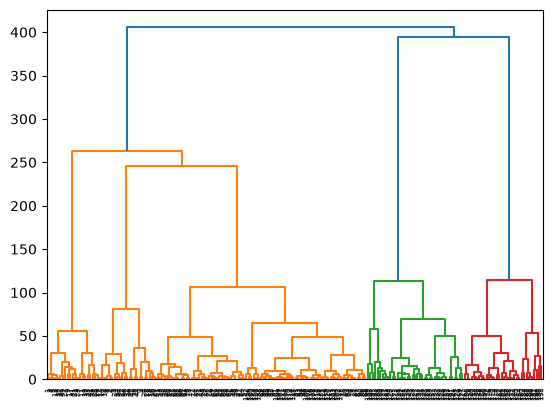

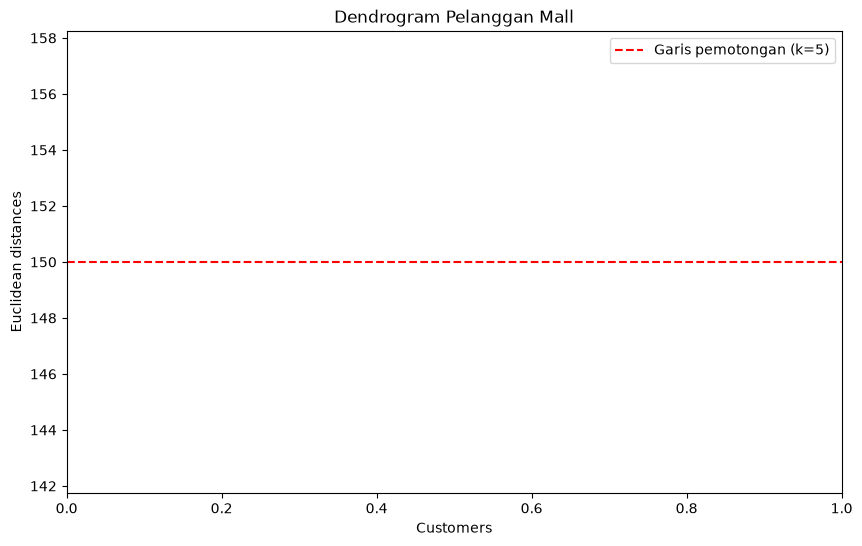

In [6]:
# Build dendrogram
import scipy.cluster.hierarchy as sch

# Build dendrogram using ward distance
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.figure(figsize=(10, 6))
plt.title('Dendrogram Pelanggan Mall')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.axhline(y=150, color='r', linestyle='--', label='Garis pemotongan (k=5)')
plt.legend()
plt.show()


## Langkah 5: Membuat model Agglomerative


In [7]:
# Build Cluster using Agglomerative Method
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)
print('Jumlah data terklaster:', len(y_hc))


Jumlah data terklaster: 200


## Langkah 6: Visualisasi klaster


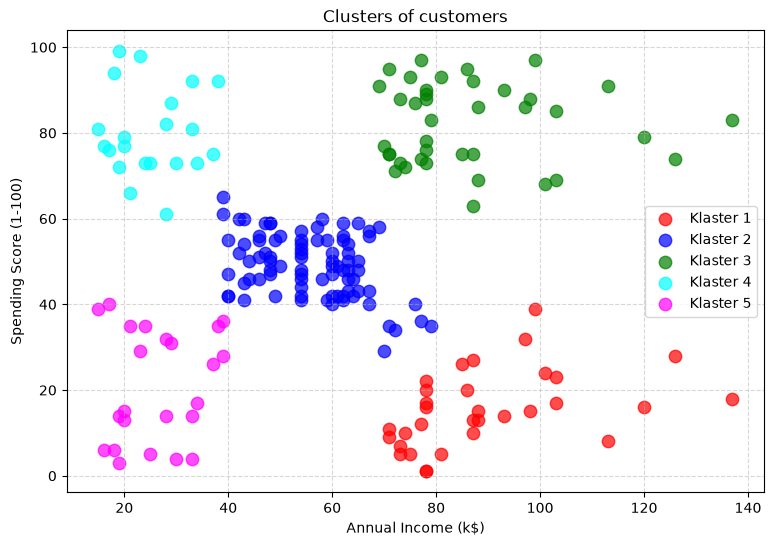

In [8]:
# Visualize The Result
plt.figure(figsize=(9, 6))
plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s=80, c='red', label='Klaster 1', alpha=0.7)
plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s=80, c='blue', label='Klaster 2', alpha=0.7)
plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s=80, c='green', label='Klaster 3', alpha=0.7)
plt.scatter(X[y_hc == 3, 0], X[y_hc == 3, 1], s=80, c='cyan', label='Klaster 4', alpha=0.7)
plt.scatter(X[y_hc == 4, 0], X[y_hc == 4, 1], s=80, c='magenta', label='Klaster 5', alpha=0.7)
plt.title('Clusters of customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## Langkah 7: Evaluasi hasil klaster


In [9]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

sil_score = silhouette_score(X, y_hc)
dbi_score = davies_bouldin_score(X, y_hc)

print(f'Silhouette Score: {sil_score:.4f}')
print(f'Davies-Bouldin Index: {dbi_score:.4f}')


Silhouette Score: 0.5530
Davies-Bouldin Index: 0.5782


## Analisis

Dendrogram dengan metode Ward memperlihatkan tiga percabangan utama di bagian atas, namun pemotongan garis jarak pada rentang 100 hingga 150 memotong lima garis vertikal terpanjang. Model dengan k=5 menghasilkan silhouette score sekitar 0,5526 dan DBI 0,5783, yang menunjukkan struktur klaster terpisah dengan baik. Lima kelompok ini memetakan nasabah secara proporsional dari segmen berpendapatan rendah hingga tinggi serta pengeluaran hemat hingga konsumtif.
